In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("dhruvildave/billboard-the-hot-100-songs")

print("Path to dataset files:", path)

100%|██████████| 3.05M/3.05M [00:00<00:00, 84.6MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/dhruvildave/billboard-the-hot-100-songs/versions/11


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/top-spotify-songs-in-73-countries-daily-updated")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'top-spotify-songs-in-73-countries-daily-updated' dataset.
Path to dataset files: /kaggle/input/top-spotify-songs-in-73-countries-daily-updated


In [7]:
import pandas as pd
import numpy as np
import os

# Kagglehub'dan gelen Billboard yolunu buraya ekliyoruz (Örn: çıktıdaki path değişkeni)
# Dosya adını klasör içeriğine göre teyit edebilirsiniz (genellikle 'charts.csv')
billboard_path = "/root/.cache/kagglehub/datasets/dhruvildave/billboard-the-hot-100-songs/versions/11/charts.csv"

df_billboard = pd.read_csv(billboard_path)

# 1.1: Sütun tipleri ve non-null sayıları
print("--- Billboard Info ---")
print(df_billboard.info())

# 1.2: İlk 5 satır
print("\n--- İlk 5 Satır ---")
display(df_billboard.head())

# 1.3: Eksik değer ve kopya kontrolü
print("\n--- Eksik Değerler ---")
print(df_billboard.isna().sum())
print("Tekrarlayan satır sayısı:", df_billboard.duplicated().sum())

--- Billboard Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 330087 entries, 0 to 330086
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   date            330087 non-null  object 
 1   rank            330087 non-null  int64  
 2   song            330087 non-null  object 
 3   artist          330087 non-null  object 
 4   last-week       297775 non-null  float64
 5   peak-rank       330087 non-null  int64  
 6   weeks-on-board  330087 non-null  int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 17.6+ MB
None

--- İlk 5 Satır ---


,date,rank,song,artist,last-week,peak-rank,weeks-on-board
0,2021-11-06,1,Easy On Me,Adele,1.0,1,3
1,2021-11-06,2,Stay,The Kid LAROI & Justin Bieber,2.0,1,16
2,2021-11-06,3,Industry Baby,Lil Nas X & Jack Harlow,3.0,1,14
3,2021-11-06,4,Fancy Like,Walker Hayes,4.0,3,19
4,2021-11-06,5,Bad Habits,Ed Sheeran,5.0,2,18



--- Eksik Değerler ---
date                  0
rank                  0
song                  0
artist                0
last-week         32312
peak-rank             0
weeks-on-board        0
dtype: int64
Tekrarlayan satır sayısı: 0


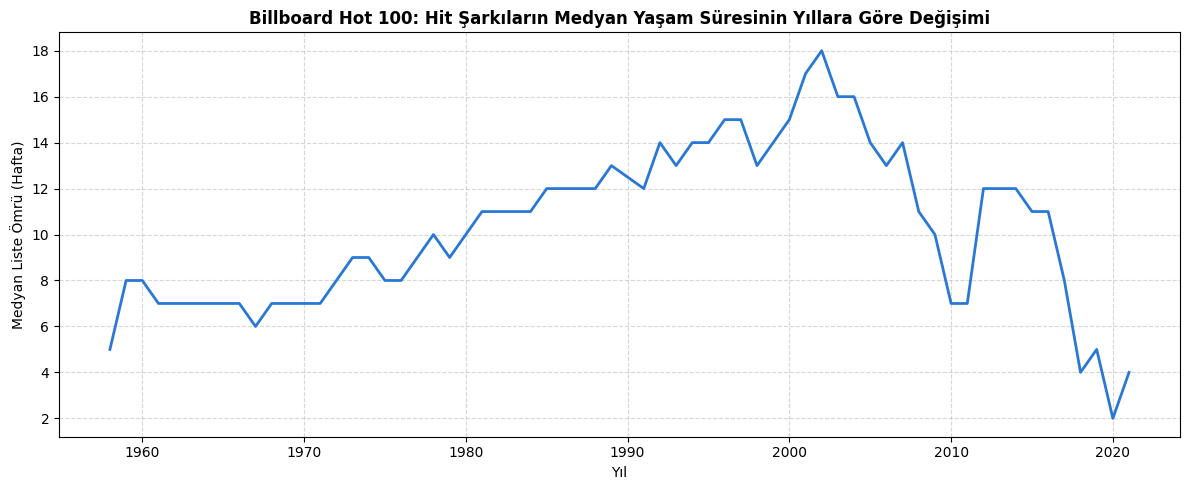

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Tarih sütununu datetime formatına çevirelim
df_billboard['date'] = pd.to_datetime(df_billboard['date'])
df_billboard['year'] = df_billboard['date'].dt.year

# Her bir şarkı-sanatçı ikilisinin listede kaldığı max süreyi (weeks-on-board) bulalım
# Veya yıllara göre ortalama/medyan weeks-on-board değerini inceleyelim:
yearly_lifespan = df_billboard.groupby(['song', 'artist', df_billboard['date'].dt.year])['weeks-on-board'].max().reset_index()
yearly_avg = yearly_lifespan.groupby('date')['weeks-on-board'].median().reset_index()

# Grafik Çizimi (Statik Grafik 1)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(yearly_avg['date'], yearly_avg['weeks-on-board'], color='#2a78d6', linewidth=2)

ax.set_title("Billboard Hot 100: Hit Şarkıların Medyan Yaşam Süresinin Yıllara Göre Değişimi", fontsize=12, fontweight='bold')
ax.set_xlabel("Yıl", fontsize=10)
ax.set_ylabel("Medyan Liste Ömrü (Hafta)", fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)

fig.tight_layout()
plt.show()

Bulunan Spotify CSV dosyaları: ['/kaggle/input/top-spotify-songs-in-73-countries-daily-updated/universal_top_spotify_songs.csv']


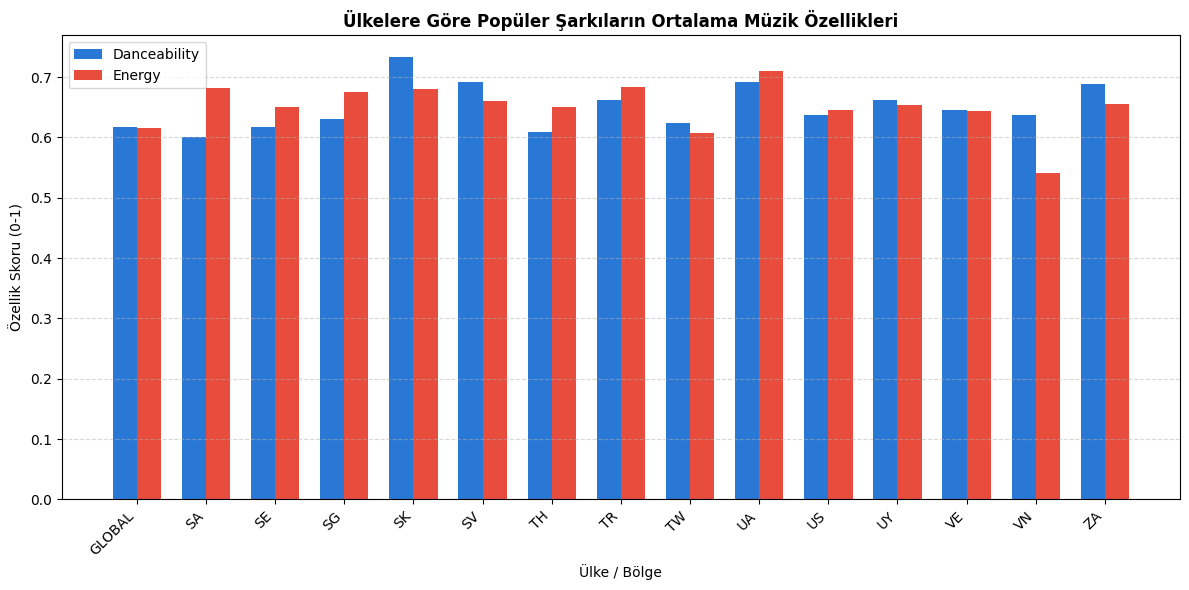

In [9]:
# Kagglehub'dan inen Spotify veri setinin yolunu kontrol edelim (Çıktıdaki yola göre güncelleyebilirsiniz)
# Genellikle 'universal_top_spotify_songs.csv' adıyla bulunur.
import glob

spotify_dir = "/kaggle/input/top-spotify-songs-in-73-countries-daily-updated"
# Eğer kagglehub farklı bir cache klasörüne indirdiyse glob ile arayabiliriz:
csv_files = glob.glob(f"{spotify_dir}/**/*.csv", recursive=True)

if not csv_files:
    # Alternatif cache yolu kontrolü
    spotify_dir = "/root/.cache/kagglehub/datasets/asaniczka/top-spotify-songs-in-73-countries-daily-updated"
    csv_files = glob.glob(f"{spotify_dir}/**/*.csv", recursive=True)

print("Bulunan Spotify CSV dosyaları:", csv_files)

# Dosyayı okutalım (İlk dosyayı seçiyoruz)
if csv_files:
    df_spotify = pd.read_csv(csv_files[0], nrows=50000) # Performans için ilk 50k satır örneklemi

    # Ülkelere göre ortalama dans edilebilirlik (danceability) veya enerji (energy) kıyaslaması
    # Ülkesi boş olanları GLOBAL yapalım
    df_spotify['country'] = df_spotify['country'].fillna('GLOBAL')

    # En çok veri bulunan ilk 15 ülkeyi seçelim
    top_countries = df_spotify['country'].value_counts().head(15).index
    df_filtered = df_spotify[df_spotify['country'].isin(top_countries)]

    country_audio = df_filtered.groupby('country')[['danceability', 'energy']].mean().reset_index()

    # Statik Grafik 2: Ülkelere Göre Dans Edilebilirlik ve Enerji Karşılaştırması
    fig, ax = plt.subplots(figsize=(12, 6))

    bar_width = 0.35
    x = range(len(country_audio))

    ax.bar([i - bar_width/2 for i in x], country_audio['danceability'], width=bar_width, label='Danceability', color='#2a78d6')
    ax.bar([i + bar_width/2 for i in x], country_audio['energy'], width=bar_width, label='Energy', color='#e74c3c')

    ax.set_title("Ülkelere Göre Popüler Şarkıların Ortalama Müzik Özellikleri", fontsize=12, fontweight='bold')
    ax.set_xlabel("Ülke / Bölge", fontsize=10)
    ax.set_ylabel("Özellik Skoru (0-1)", fontsize=10)
    ax.set_xticks(list(x))
    ax.set_xticklabels(country_audio['country'], rotation=45, ha='right')
    ax.legend()
    ax.grid(axis='y', linestyle='--', alpha=0.5)

    fig.tight_layout()
    plt.show()
else:
    print("Spotify CSV dosyası bulunamadı, lütfen dosya yolunu kontrol edin.")

In [13]:
import os
import kagglehub

def download_datasets():
    # Ham verilerin saklanacağı dizin
    raw_dir = "data/raw"
    os.makedirs(raw_dir, exist_ok=True)

    print("Billboard Hot 100 veri seti indiriliyor...")
    path_bb = kagglehub.dataset_download("dhruvildave/billboard-the-hot-100-songs")
    print(f"Billboard indirildi: {path_bb}")

    print("Top Spotify Songs veri seti indiriliyor...")
    path_sp = kagglehub.dataset_download("asaniczka/top-spotify-songs-in-73-countries-daily-updated")
    print(f"Spotify indirildi: {path_sp}")

    print("İndirme işlemi tamamlandı. Lütfen ham CSV dosyalarını data/raw/ altına taşıyın/bağlayın.")

if __name__ == "__main__":
    download_datasets()

Billboard Hot 100 veri seti indiriliyor...
Using Colab cache for faster access to the 'billboard-the-hot-100-songs' dataset.
Billboard indirildi: /kaggle/input/billboard-the-hot-100-songs
Top Spotify Songs veri seti indiriliyor...
Using Colab cache for faster access to the 'top-spotify-songs-in-73-countries-daily-updated' dataset.
Spotify indirildi: /kaggle/input/top-spotify-songs-in-73-countries-daily-updated
İndirme işlemi tamamlandı. Lütfen ham CSV dosyalarını data/raw/ altına taşıyın/bağlayın.


In [17]:
import os
import pandas as pd
import glob

# 1. Billboard temizliğini çalıştıralım
def clean_billboard(input_path, output_path):
    print("Billboard verisi işleniyor ve temizleniyor...")
    df = pd.read_csv(input_path)

    # Tarih formatını standartlaştır
    df['date'] = pd.to_datetime(df['date'])
    df['year'] = df['date'].dt.year

    # Eşleştirme için temiz sütunlar oluştur
    df['song_clean'] = df['song'].str.lower().str.strip()
    df['artist_clean'] = df['artist'].str.lower().str.strip()

    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    df.to_csv(output_path, index=False)
    print(f"Billboard başarıyla kaydedildi: {output_path} ({len(df)} satır)")
    return df

# 2. Spotify temizliğini çalıştıralım
def clean_spotify(input_path, output_path):
    print("Spotify verisi işleniyor ve temizleniyor...")
    df = pd.read_csv(input_path)

    # Tarih ve eksik ülke dönüşümleri
    df['snapshot_date'] = pd.to_datetime(df['snapshot_date'])
    df['country'] = df['country'].fillna('GLOBAL')

    df['song_clean'] = df['name'].str.lower().str.strip()
    df['artist_clean'] = df['artists'].str.lower().str.strip()

    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    df.to_csv(output_path, index=False)
    print(f"Spotify başarıyla kaydedildi: {output_path} ({len(df)} satır)")
    return df

# Dosya yollarını otomatik bulup çalıştıralım
bb_csv = "/root/.cache/kagglehub/datasets/dhruvildave/billboard-the-hot-100-songs/versions/11/charts.csv"
sp_files = glob.glob("/root/.cache/kagglehub/datasets/asaniczka/top-spotify-songs-in-73-countries-daily-updated/**/*.csv", recursive=True)
if not sp_files:
    sp_files = glob.glob("/kaggle/input/top-spotify-songs-in-73-countries-daily-updated/**/*.csv", recursive=True)

# Fonksiyonları tetikleyelim
df_bb_clean = clean_billboard(bb_csv, "data/processed/billboard_clean.csv")

if sp_files:
    df_sp_clean = clean_spotify(sp_files[0], "data/processed/spotify_clean.csv")
else:
    print("Spotify CSV dosyası otomatik yolda bulunamadı.")

Billboard verisi işleniyor ve temizleniyor...
Billboard başarıyla kaydedildi: data/processed/billboard_clean.csv (330087 satır)
Spotify verisi işleniyor ve temizleniyor...
Spotify başarıyla kaydedildi: data/processed/spotify_clean.csv (2110316 satır)
